# **Amazon Prime TV Shows and Movies — Exploratory Data Analysis**

##### **Project Type** — Exploratory Data Analysis (EDA)  
##### **Contribution** — Individual  
##### **Tools** — Python, Pandas, NumPy, Matplotlib and Seaborn

# **Project Summary**

This project performs an exploratory data analysis of an Amazon Prime catalogue containing **9,868 unique titles** released between **1912 and 2022**. The dataset combines descriptive catalogue information—title, content type, release year, age certification, runtime, genres and production countries—with audience and platform metrics such as IMDb score, IMDb votes, TMDB score and TMDB popularity. The purpose of the analysis is to understand the composition, diversity, quality and popularity of Amazon Prime's movie and television offering and to translate those findings into practical content and product decisions.

The analysis begins with data-quality assessment. The original file contains **3 duplicate rows**, which are removed. Missing values are handled according to their meaning rather than through indiscriminate imputation. Missing `seasons` values are retained for movies because seasons apply only to shows. Missing age certifications are labelled **Not Rated / Unknown** for categorical analysis. Missing numerical ratings are not filled with averages because doing so would create artificial audience scores and distort relationships. Genre and production-country fields are converted from string representations of lists into real Python lists and then exploded when category-level analysis is needed.

The catalogue is highly movie-oriented: **8,511 movies (86.2%)** and **1,357 shows (13.8%)**. Drama, comedy, thriller, action and romance form the largest genre groups, while the United States, India, the United Kingdom and Canada contribute the greatest number of titles. Release volume increases sharply in recent decades, particularly after 2010, although the 2022 count should be interpreted carefully because the dataset may represent only a partial year.

Quality and popularity analysis reveals clear differences between content formats. Shows have a median IMDb score of **7.3**, compared with **5.9** for movies. Median runtime is approximately **91 minutes** for movies and **33 minutes** per show episode, while the typical show has **1 season**. IMDb and TMDB scores show a moderately strong positive correlation of approximately **0.58**, but popularity and quality are not interchangeable: a title can be highly visible without being among the highest-rated titles.

The notebook contains more than twenty visualisations covering univariate, bivariate and multivariate analysis. Each chart includes its rationale, principal insight and potential business impact. The final recommendations focus on balancing catalogue scale with quality, strengthening high-performing genres and regional content, improving metadata completeness, and using rating, vote and popularity signals together when planning acquisition, promotion and recommendation strategies.

# **GitHub Link**

Add the final repository URL after uploading this notebook and dataset to GitHub.

# **Problem Statement**

Amazon Prime offers a large and diverse catalogue of movies and television shows. However, catalogue size alone does not explain whether the platform has an effective balance of formats, genres, countries, age segments, quality and popularity. The analysis must identify content patterns, gaps and high-performing segments while accounting for incomplete metadata and the different meanings of variables for movies and shows.

#### **Business Objective**

Analyse the Amazon Prime catalogue to identify content-composition trends, audience-quality signals, popularity drivers and regional or genre opportunities. The findings should support content acquisition, catalogue curation, recommendation, merchandising and metadata-improvement decisions.

# ***Let's Begin***

## **1. Know Your Data**

### Import Libraries

In [1]:
import ast
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 120)
sns.set_theme(style='whitegrid', context='notebook')

### Dataset Loading

In [2]:
# The notebook first looks for the friendly file name in the current Colab/session folder.
# If it is absent in Google Colab, an upload dialog is shown.
DATA_FILE = 'amazon_prime_titles.csv'

if not os.path.exists(DATA_FILE):
    try:
        from google.colab import files
        uploaded = files.upload()
        DATA_FILE = next(iter(uploaded))
    except Exception as exc:
        raise FileNotFoundError(
            "Place amazon_prime_titles.csv in the notebook folder or upload it in Colab."
        ) from exc

df_raw = pd.read_csv(DATA_FILE)
df = df_raw.copy()
print(f'Dataset loaded successfully: {df.shape[0]:,} rows × {df.shape[1]} columns')

Dataset loaded successfully: 9,871 rows × 15 columns


### Dataset First View

In [3]:
display(df.head())

,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,ts20945,The Three Stooges,SHOW,"The Three Stooges were an American vaudeville and comedy team active from 1922 until 1970, best known for their 190 ...",1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'fantasy', 'horror']",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6
1,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal engineer Johnnie Gray's beloved locomotive, 'The General'—with Johnnie...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy', 'european']",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0
2,tm82253,The Best Years of Our Lives,MOVIE,It's the hope that sustains the spirit of every GI: the dream of the day when he will finally return home. For three...,1946,NaN,171,"['romance', 'war', 'drama']",['US'],NaN,tt0036868,8.1,63026.0,8.435,7.8
3,tm83884,His Girl Friday,MOVIE,"Hildy, the journalist former wife of newspaper editor Walter Burns, visits his office to inform him that she's engag...",1940,NaN,92,"['comedy', 'drama', 'romance']",['US'],NaN,tt0032599,7.8,57835.0,11.270,7.4
4,tm56584,In a Lonely Place,MOVIE,An aspiring actress begins to suspect that her temperamental boyfriend is a murderer.,1950,NaN,94,"['thriller', 'drama', 'romance']",['US'],NaN,tt0042593,7.9,30924.0,8.273,7.6


### Dataset Rows and Columns

In [4]:
print('Number of rows   :', df.shape[0])
print('Number of columns:', df.shape[1])
print('\nColumns:')
print(df.columns.tolist())

Number of rows   : 9871
Number of columns: 15

Columns:
['id', 'title', 'type', 'description', 'release_year', 'age_certification', 'runtime', 'genres', 'production_countries', 'seasons', 'imdb_id', 'imdb_score', 'imdb_votes', 'tmdb_popularity', 'tmdb_score']


### Dataset Information

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9871 entries, 0 to 9870
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    9871 non-null   object 
 1   title                 9871 non-null   object 
 2   type                  9871 non-null   object 
 3   description           9752 non-null   object 
 4   release_year          9871 non-null   int64  
 5   age_certification     3384 non-null   object 
 6   runtime               9871 non-null   int64  
 7   genres                9871 non-null   object 
 8   production_countries  9871 non-null   object 
 9   seasons               1357 non-null   float64
 10  imdb_id               9204 non-null   object 
 11  imdb_score            8850 non-null   float64
 12  imdb_votes            8840 non-null   float64
 13  tmdb_popularity       9324 non-null   float64
 14  tmdb_score            7789 non-null   float64
dtypes: float64(5), int64(

#### Descriptive Statistics

In [6]:
display(df.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,9871,9868,tm89134,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,9871,9737,The Hound of the Baskervilles,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,9871,2,MOVIE,8514,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,9752,9734,No overview found.,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,9871.0,NaN,NaN,NaN,2001.327221,25.810071,1912.0,1995.5,2014.0,2018.0,2022.0
age_certification,3384,11,R,1249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
runtime,9871.0,NaN,NaN,NaN,85.973052,33.512466,1.0,65.0,89.0,102.0,549.0
genres,9871,2028,['drama'],908,NaN,NaN,NaN,NaN,NaN,NaN,NaN
production_countries,9871,497,['US'],4810,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seasons,1357.0,NaN,NaN,NaN,2.791452,4.148958,1.0,1.0,1.0,3.0,51.0


#### Duplicate Values

In [7]:
duplicate_count = df.duplicated().sum()
print('Duplicate rows:', duplicate_count)

Duplicate rows: 3


#### Missing Values

In [8]:
missing_table = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_percentage': (df.isna().mean() * 100).round(2)
}).sort_values('missing_percentage', ascending=False)
display(missing_table)

,missing_count,missing_percentage
seasons,8514,86.25
age_certification,6487,65.72
tmdb_score,2082,21.09
imdb_votes,1031,10.44
imdb_score,1021,10.34
imdb_id,667,6.76
tmdb_popularity,547,5.54
description,119,1.21
runtime,0,0.00
title,0,0.00


### What did we learn about the dataset?

- The raw dataset contains **9,871 rows and 15 columns**.
- It includes catalogue metadata together with IMDb and TMDB performance measures.
- There are **3 exact duplicate rows**.
- `seasons` is structurally missing for movies and should not be treated as ordinary data loss.
- Age certification and some rating fields have material missingness.
- `genres` and `production_countries` are stored as text-formatted lists and need parsing before category analysis.

## **2. Understanding Your Variables**

### Variables Description

| Variable | Description |
|---|---|
| `id` | Internal title identifier; prefixes generally distinguish shows and movies. |
| `title` | Name of the movie or show. |
| `type` | Content format: `MOVIE` or `SHOW`. |
| `description` | Plot or catalogue description. |
| `release_year` | Original release year. |
| `age_certification` | Audience certification such as R, PG-13, TV-MA or TV-PG. |
| `runtime` | Movie duration or episode duration in minutes. |
| `genres` | One or more genres stored as a list-like string. |
| `production_countries` | One or more production-country codes stored as a list-like string. |
| `seasons` | Number of seasons for shows; not applicable to movies. |
| `imdb_id` | IMDb title identifier. |
| `imdb_score` | IMDb user rating. |
| `imdb_votes` | Number of IMDb votes. |
| `tmdb_popularity` | TMDB popularity indicator. |
| `tmdb_score` | TMDB user rating. |

### Unique Values for Each Variable

In [9]:
unique_summary = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'unique_values': df.nunique(dropna=False),
    'missing_values': df.isna().sum()
})
display(unique_summary)

for column in ['type', 'age_certification']:
    print(f'\n{column}:')
    print(df[column].value_counts(dropna=False).head(20))

,dtype,unique_values,missing_values
id,object,9868,0
title,object,9737,0
type,object,2,0
description,object,9735,119
release_year,int64,110,0
age_certification,object,12,6487
runtime,int64,207,0
genres,object,2028,0
production_countries,object,497,0
seasons,float64,33,8514



type:
type
MOVIE    8514
SHOW     1357
Name: count, dtype: int64

age_certification:
age_certification
NaN      6487
R        1249
PG-13     588
PG        582
G         269
TV-MA     217
TV-14     188
TV-PG      91
TV-Y       78
TV-G       57
TV-Y7      52
NC-17      13
Name: count, dtype: int64


## **3. Data Wrangling**

### Data Wrangling Code

In [10]:
def parse_list_column(value):
    # Safely convert a list-like string to a Python list.
    if pd.isna(value):
        return []
    if isinstance(value, list):
        return value
    try:
        parsed = ast.literal_eval(str(value))
        return parsed if isinstance(parsed, list) else []
    except (ValueError, SyntaxError):
        return []

# 1. Remove exact duplicates.
df = df.drop_duplicates().copy()

# 2. Fill only descriptive/categorical fields where a label is analytically useful.
df['description'] = df['description'].fillna('Description unavailable')
df['age_certification_clean'] = df['age_certification'].fillna('Not Rated / Unknown')

# 3. Parse list-like fields.
df['genres_list'] = df['genres'].apply(parse_list_column)
df['production_countries_list'] = df['production_countries'].apply(parse_list_column)

# 4. Create derived variables.
df['decade'] = (df['release_year'] // 10) * 10
df['content_age'] = df['release_year'].max() - df['release_year']
df['imdb_votes_log'] = np.log10(df['imdb_votes'].fillna(0) + 1)
df['tmdb_popularity_log'] = np.log10(df['tmdb_popularity'].fillna(0) + 1)

# 5. Create exploded tables for genre and country analysis.
genre_df = df.explode('genres_list').rename(columns={'genres_list': 'genre'})
genre_df = genre_df[genre_df['genre'].notna() & genre_df['genre'].ne('')]

country_df = df.explode('production_countries_list').rename(
    columns={'production_countries_list': 'country'}
)
country_df = country_df[country_df['country'].notna() & country_df['country'].ne('')]
country_df['country'] = country_df['country'].replace({'XX': 'Unknown'})

print(f'Cleaned dataset: {df.shape[0]:,} rows × {df.shape[1]} columns')
print('Remaining duplicate rows:', df.duplicated(subset=df_raw.columns.tolist()).sum())

Cleaned dataset: 9,868 rows × 22 columns
Remaining duplicate rows: 0


### Validation Checks

In [11]:
assert df.duplicated(subset=df_raw.columns.tolist()).sum() == 0
assert set(df['type'].dropna().unique()).issubset({'MOVIE', 'SHOW'})
assert df['release_year'].between(1900, 2030).all()
assert (df['runtime'] >= 0).all()
print('Validation checks passed.')

Validation checks passed.


### Manipulations and Initial Insights

- Exact duplicate rows were removed.
- Missing numeric ratings were retained as missing rather than imputed, preserving the authenticity of audience measures.
- Missing age certification was converted to a visible `Not Rated / Unknown` category.
- Genres and production countries were parsed and exploded into separate analytical tables.
- Decade, content age and log-scaled popularity/vote variables were created for clearer trend and outlier analysis.
- Movies and shows are analysed separately when runtime or seasons have different meanings.

## **4. Data Visualisation, Storytelling and Experimentation**

In [12]:
def finish_plot(title, xlabel='', ylabel=''):
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.show()

#### **Chart 1 — Catalogue Composition by Content Type**

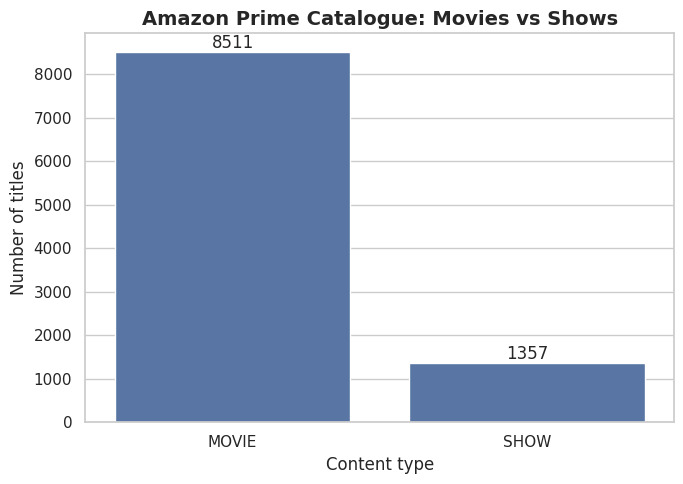

In [13]:
plt.figure(figsize=(7, 5))
order = df['type'].value_counts().index
ax = sns.countplot(data=df, x='type', order=order, color='C0')
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f')
finish_plot('Amazon Prime Catalogue: Movies vs Shows', 'Content type', 'Number of titles')

**Why this chart?** A count plot directly compares the two primary content formats.  
**Insight.** Movies account for **86.2%** of unique titles, so the catalogue is strongly movie-led.  
**Business impact.** Amazon can assess whether the movie-heavy mix matches engagement goals or whether additional episodic originals are needed to strengthen repeat viewing and retention.

#### **Chart 2 — Titles Released by Decade**

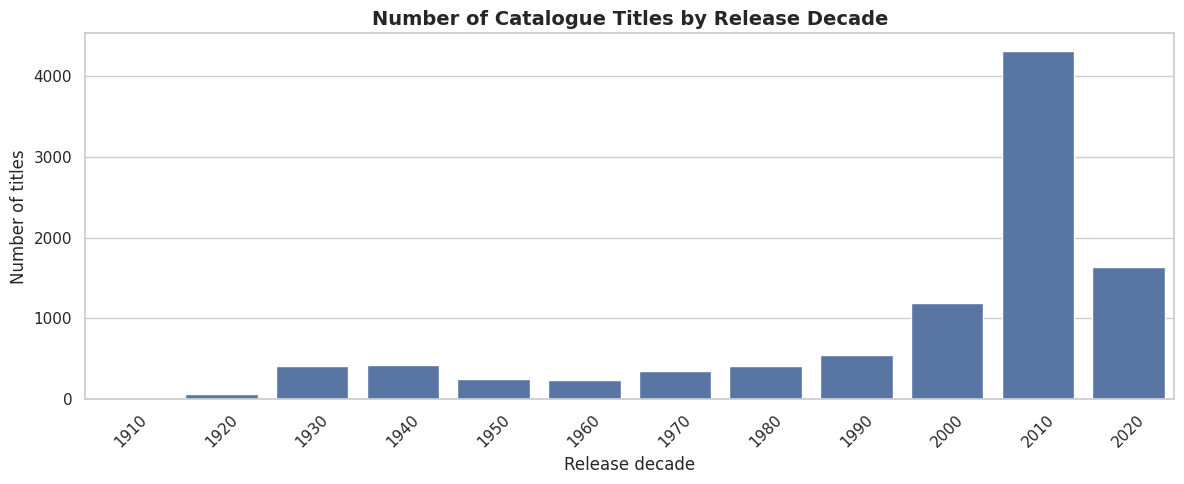

In [14]:
decade_counts = df['decade'].value_counts().sort_index()
plt.figure(figsize=(12, 5))
sns.barplot(x=decade_counts.index.astype(str), y=decade_counts.values, color='C0')
plt.xticks(rotation=45)
finish_plot('Number of Catalogue Titles by Release Decade', 'Release decade', 'Number of titles')

**Why this chart?** Grouping by decade makes the long historical range readable.  
**Insight.** The catalogue expands sharply from the 2000s and is dominated by content released after 2010, while still retaining a meaningful classic-film archive.  
**Business impact.** The platform can maintain separate merchandising strategies for contemporary discovery and classic-cinema audiences.

#### **Chart 3 — Annual Release Trend by Type**

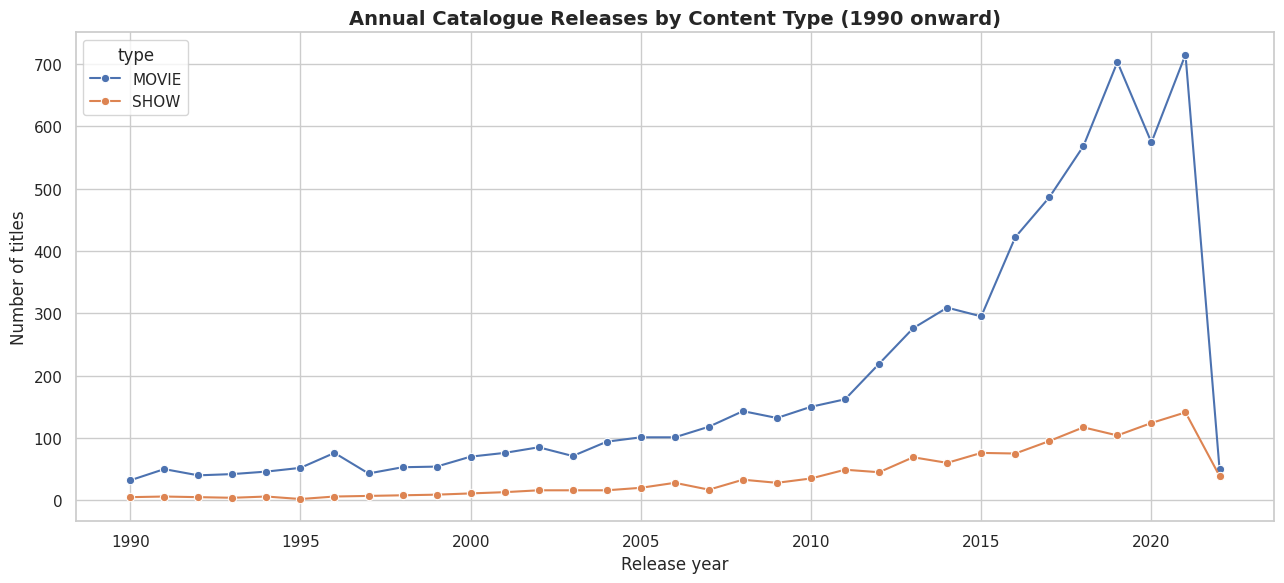

In [15]:
yearly_type = df.groupby(['release_year', 'type']).size().reset_index(name='titles')
recent_yearly = yearly_type[yearly_type['release_year'] >= 1990]
plt.figure(figsize=(13, 6))
sns.lineplot(data=recent_yearly, x='release_year', y='titles', hue='type', marker='o')
finish_plot('Annual Catalogue Releases by Content Type (1990 onward)', 'Release year', 'Number of titles')

**Why this chart?** A multi-series line chart shows both time trends and format differences.  
**Insight.** Release volume grows strongly after 2010, with movies driving most of the increase. The 2022 drop should not automatically be treated as market decline because the data may cover only part of that year.  
**Business impact.** Acquisition and promotion teams should compare complete periods before making year-over-year decisions.

#### **Chart 4 — Top Age Certifications**

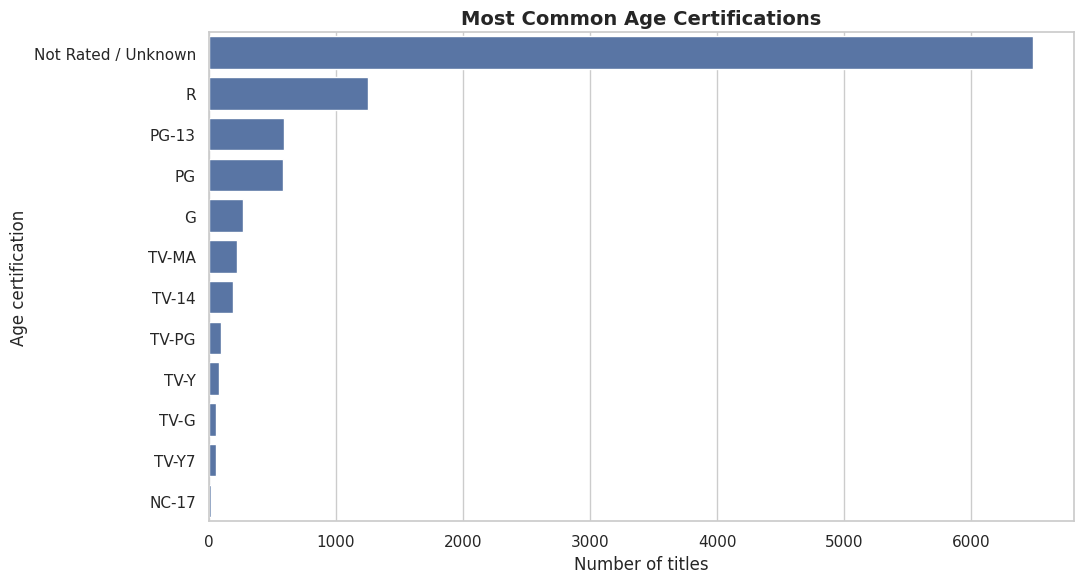

In [16]:
cert_counts = df['age_certification_clean'].value_counts().head(12)
plt.figure(figsize=(11, 6))
sns.barplot(y=cert_counts.index, x=cert_counts.values, color='C0')
finish_plot('Most Common Age Certifications', 'Number of titles', 'Age certification')

**Why this chart?** Certification categories are nominal and are best compared with horizontal bars.  
**Insight.** `Not Rated / Unknown` is the largest category, followed by R, PG-13 and PG among known certifications.  
**Business impact.** Improving certification coverage can strengthen parental controls, search filters and family-safe recommendations.

#### **Chart 5 — Movie Runtime Distribution**

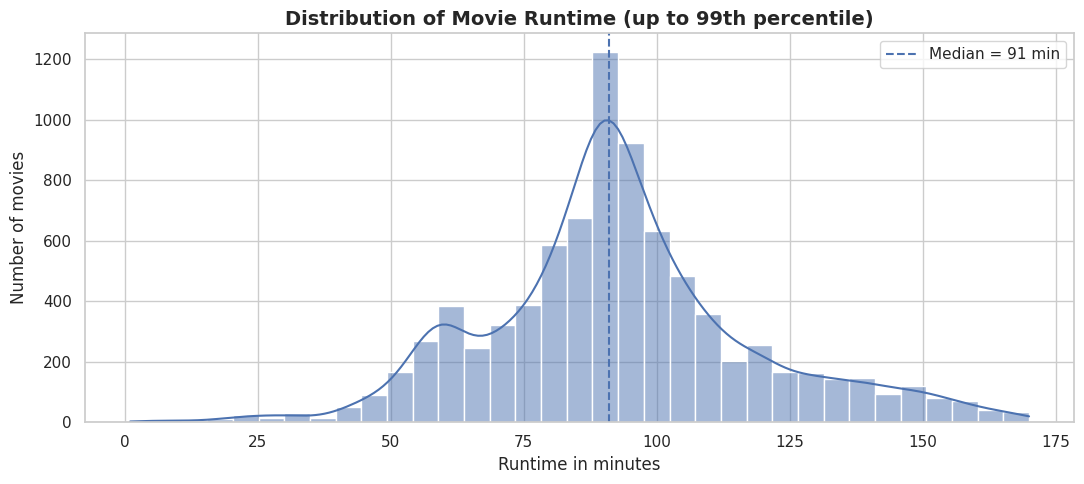

In [17]:
movie_runtime = df.loc[df['type'].eq('MOVIE'), 'runtime']
upper = movie_runtime.quantile(0.99)
plt.figure(figsize=(11, 5))
sns.histplot(movie_runtime[movie_runtime <= upper], bins=35, kde=True, color='C0')
plt.axvline(movie_runtime.median(), linestyle='--', label=f'Median = {movie_runtime.median():.0f} min')
plt.legend()
finish_plot('Distribution of Movie Runtime (up to 99th percentile)', 'Runtime in minutes', 'Number of movies')

**Why this chart?** A histogram and density curve reveal the typical movie length and skewness.  
**Insight.** The median movie runtime is **91 minutes**; most films cluster around standard feature length, with a small set of unusually short or long records.  
**Business impact.** Runtime can support “quick watch,” standard feature and long-form recommendation shelves.

#### **Chart 6 — Show Episode Runtime Distribution**

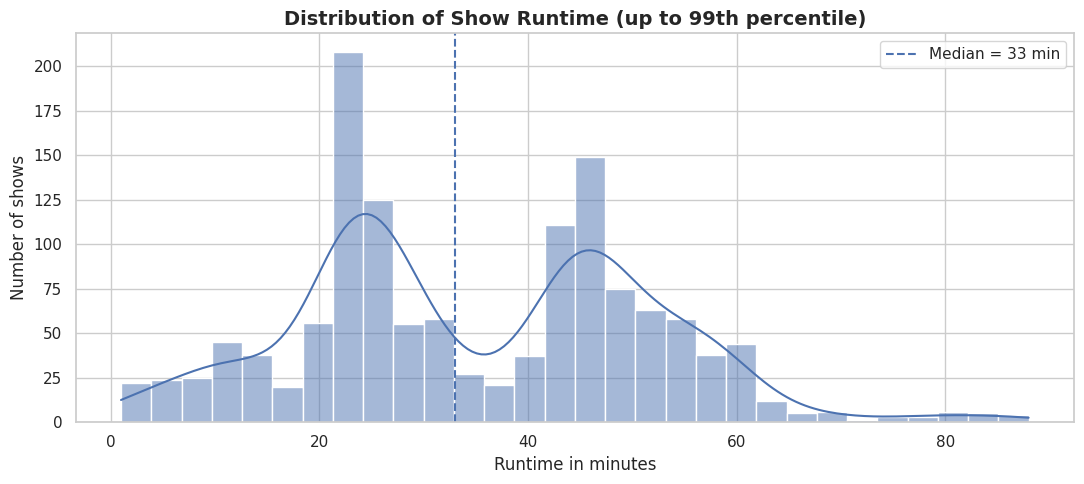

In [18]:
show_runtime = df.loc[df['type'].eq('SHOW'), 'runtime']
upper = show_runtime.quantile(0.99)
plt.figure(figsize=(11, 5))
sns.histplot(show_runtime[show_runtime <= upper], bins=30, kde=True, color='C0')
plt.axvline(show_runtime.median(), linestyle='--', label=f'Median = {show_runtime.median():.0f} min')
plt.legend()
finish_plot('Distribution of Show Runtime (up to 99th percentile)', 'Runtime in minutes', 'Number of shows')

**Why this chart?** Show runtime represents episode length and should be separated from movie duration.  
**Insight.** The median show runtime is approximately **33 minutes**, with clusters representing short-form and conventional television episodes.  
**Business impact.** Episode length can improve context-aware recommendations based on how much time a viewer has available.

#### **Chart 7 — Number of Seasons for Shows**

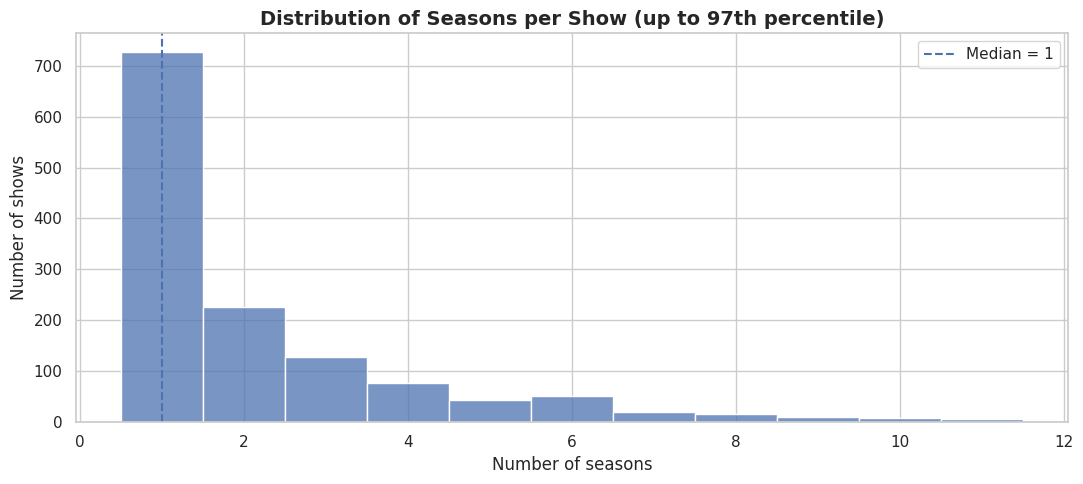

In [19]:
show_seasons = df.loc[df['type'].eq('SHOW') & df['seasons'].notna(), 'seasons']
upper = show_seasons.quantile(0.97)
plt.figure(figsize=(11, 5))
sns.histplot(show_seasons[show_seasons <= upper], discrete=True, color='C0')
plt.axvline(show_seasons.median(), linestyle='--', label=f'Median = {show_seasons.median():.0f}')
plt.legend()
finish_plot('Distribution of Seasons per Show (up to 97th percentile)', 'Number of seasons', 'Number of shows')

**Why this chart?** A discrete histogram shows whether the catalogue favours limited or long-running series.  
**Insight.** The median show has **1 season**, indicating a strong concentration of limited or newer series, with a long tail of established programmes.  
**Business impact.** Single-season titles may need renewal-status messaging, while multi-season titles are useful for binge and retention campaigns.

#### **Chart 8 — IMDb Score Distribution**

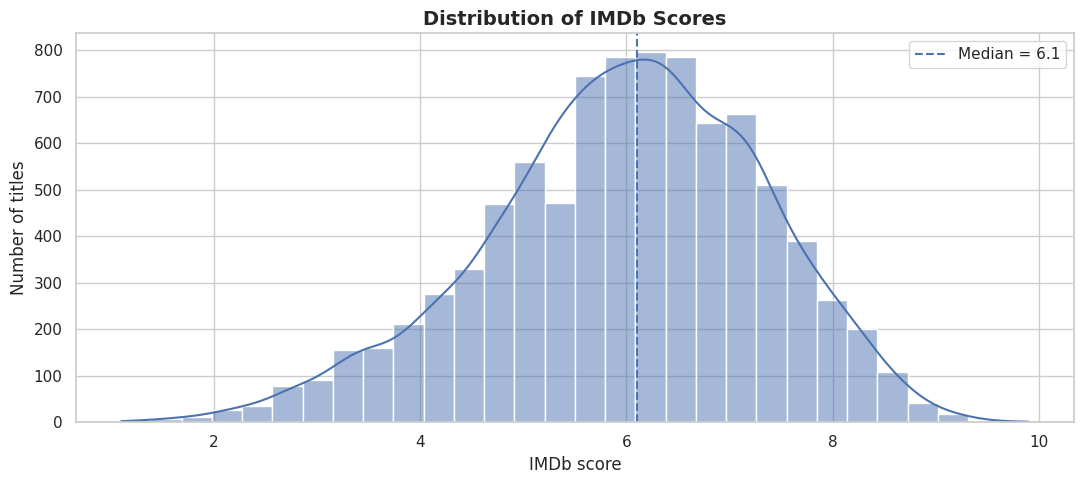

In [20]:
plt.figure(figsize=(11, 5))
sns.histplot(df['imdb_score'].dropna(), bins=30, kde=True, color='C0')
plt.axvline(df['imdb_score'].median(), linestyle='--', label=f'Median = {df.imdb_score.median():.1f}')
plt.legend()
finish_plot('Distribution of IMDb Scores', 'IMDb score', 'Number of titles')

**Why this chart?** The score distribution reveals overall catalogue quality and extreme values.  
**Insight.** Ratings are centred near the low-to-mid sixes, with relatively few titles at either extreme.  
**Business impact.** Quality tiers can be combined with vote thresholds to avoid promoting unstable ratings based on very small audiences.

#### **Chart 9 — IMDb Scores by Content Type**

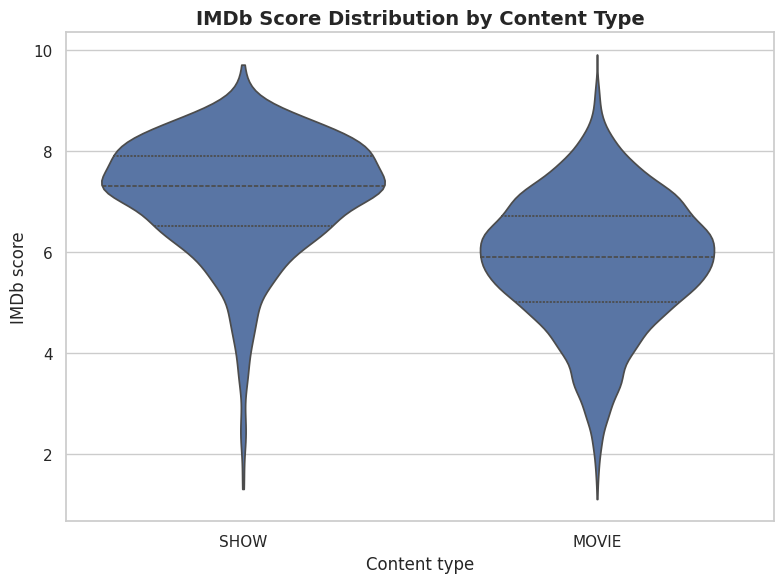

In [21]:
plt.figure(figsize=(8, 6))
sns.violinplot(data=df, x='type', y='imdb_score', inner='quartile', cut=0)
finish_plot('IMDb Score Distribution by Content Type', 'Content type', 'IMDb score')

**Why this chart?** A violin plot compares central tendency, spread and distribution shape simultaneously.  
**Insight.** Shows have a median IMDb score of **7.3**, compared with **5.9** for movies. Selection effects may contribute because series often require sustained audience interest.  
**Business impact.** High-quality series can be prioritised for retention, while movie promotion may benefit from stronger quality and audience-volume filters.

#### **Chart 10 — TMDB Score Distribution by Content Type**

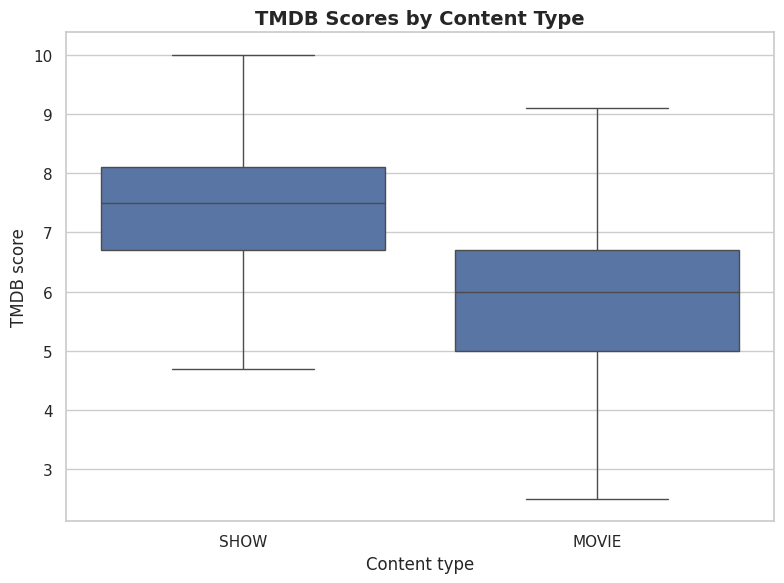

In [22]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='type', y='tmdb_score', showfliers=False)
finish_plot('TMDB Scores by Content Type', 'Content type', 'TMDB score')

**Why this chart?** A box plot offers a robust comparison when rating distributions contain outliers.  
**Insight.** Shows also tend to receive higher TMDB scores than movies, reinforcing the IMDb format difference.  
**Business impact.** Consistent evidence across platforms strengthens confidence in format-level quality comparisons.

#### **Chart 11 — IMDb Voting Volume**

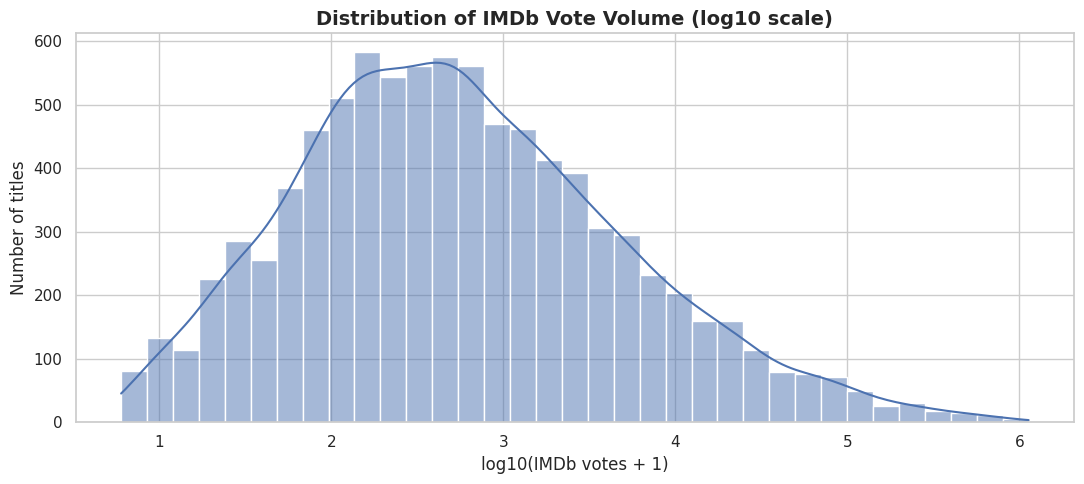

In [23]:
plt.figure(figsize=(11, 5))
sns.histplot(df.loc[df['imdb_votes'].notna(), 'imdb_votes_log'], bins=35, kde=True, color='C0')
finish_plot('Distribution of IMDb Vote Volume (log10 scale)', 'log10(IMDb votes + 1)', 'Number of titles')

**Why this chart?** Vote counts are extremely right-skewed, so a logarithmic transformation makes the full range visible.  
**Insight.** Most titles have modest voting volume, while a small group has very large audience recognition.  
**Business impact.** Score and vote volume should be considered together; a high score with few votes is less reliable than a similar score with broad participation.

#### **Chart 12 — TMDB Popularity by Content Type**

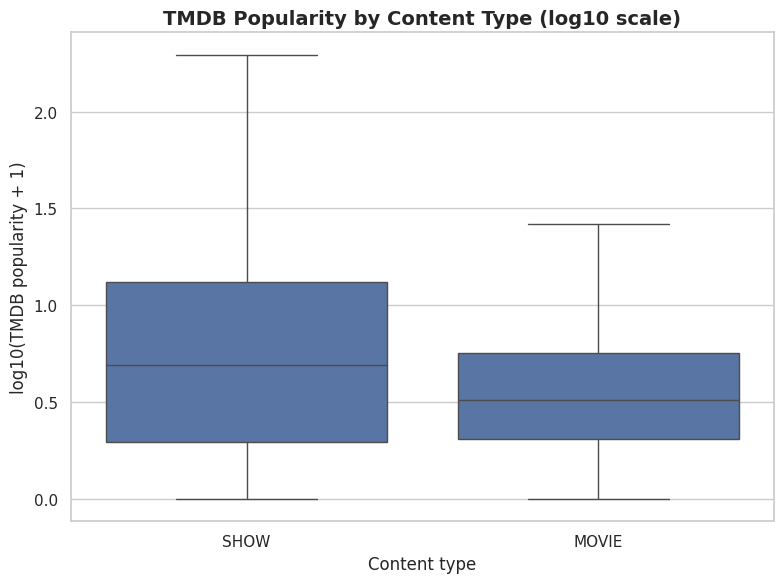

In [24]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='type', y='tmdb_popularity_log', showfliers=False)
finish_plot('TMDB Popularity by Content Type (log10 scale)', 'Content type', 'log10(TMDB popularity + 1)')

**Why this chart?** Log scaling and a box plot reduce the visual dominance of blockbuster outliers.  
**Insight.** Popularity is highly skewed for both formats, and a limited number of titles attract disproportionate attention.  
**Business impact.** The platform should distinguish dependable long-tail discovery from short-lived popularity spikes when allocating homepage space.

#### **Chart 13 — Top Genres by Catalogue Size**

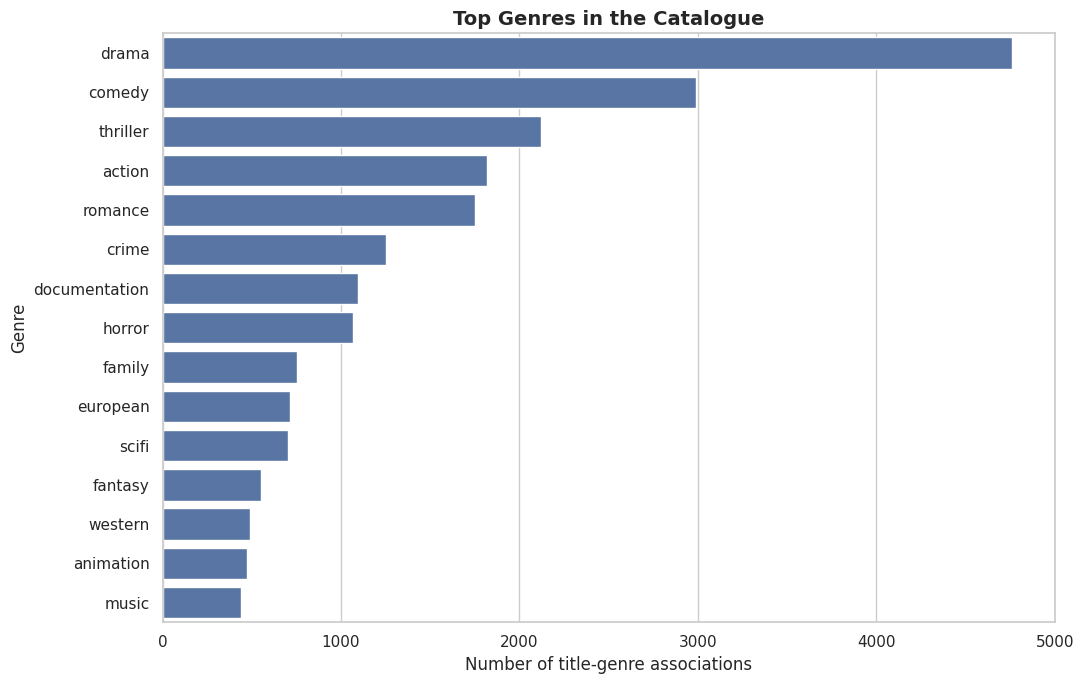

In [25]:
genre_counts = genre_df['genre'].value_counts().head(15)
plt.figure(figsize=(11, 7))
sns.barplot(y=genre_counts.index, x=genre_counts.values, color='C0')
finish_plot('Top Genres in the Catalogue', 'Number of title-genre associations', 'Genre')

**Why this chart?** Horizontal bars clearly compare many genre categories.  
**Insight.** The leading genres are **drama, comedy, thriller, action, romance**, showing a broad emphasis on mainstream narrative content. Multi-genre titles contribute to more than one category.  
**Business impact.** Genre concentration can guide acquisition-gap analysis and personalised homepage organisation.

#### **Chart 14 — Average IMDb Score by Genre**

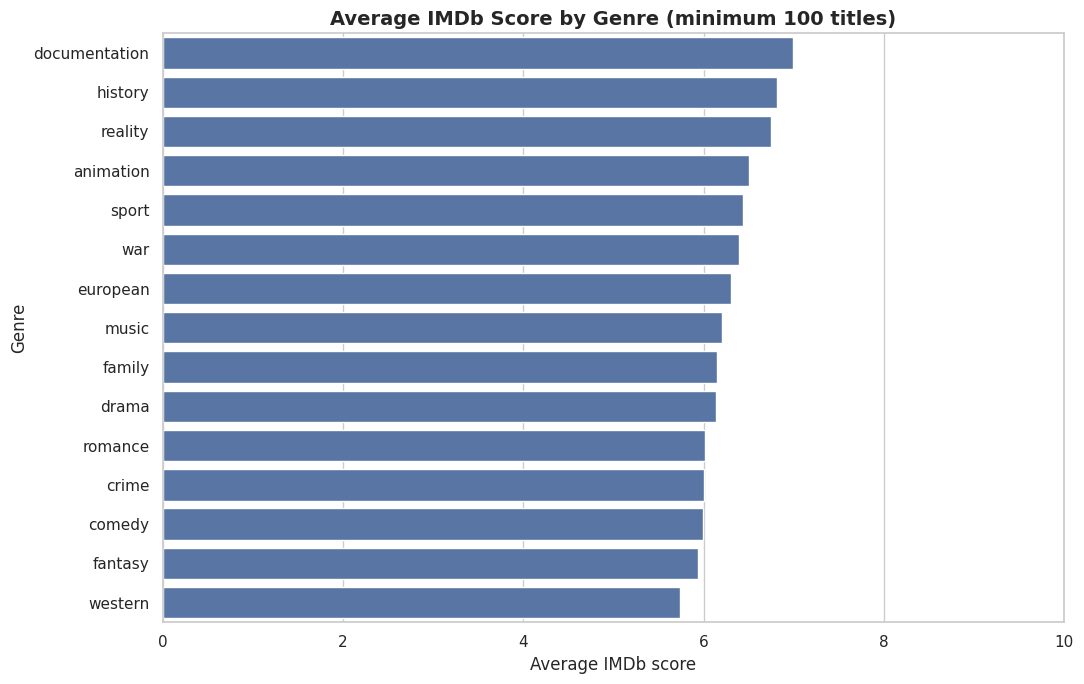

In [26]:
genre_quality = (
    genre_df.groupby('genre')
    .agg(title_count=('id', 'size'), average_imdb=('imdb_score', 'mean'))
    .query('title_count >= 100')
    .sort_values('average_imdb', ascending=False)
    .head(15)
)
plt.figure(figsize=(11, 7))
sns.barplot(data=genre_quality, y=genre_quality.index, x='average_imdb', color='C0')
plt.xlim(0, 10)
finish_plot('Average IMDb Score by Genre (minimum 100 titles)', 'Average IMDb score', 'Genre')

**Why this chart?** Applying a minimum sample threshold produces more stable genre comparisons.  
**Insight.** Documentary, history and several specialised genres achieve stronger average IMDb scores than many high-volume entertainment genres.  
**Business impact.** Smaller high-quality genres can be positioned as differentiation opportunities rather than judged only by catalogue volume.

#### **Chart 15 — Genre Popularity versus Quality**

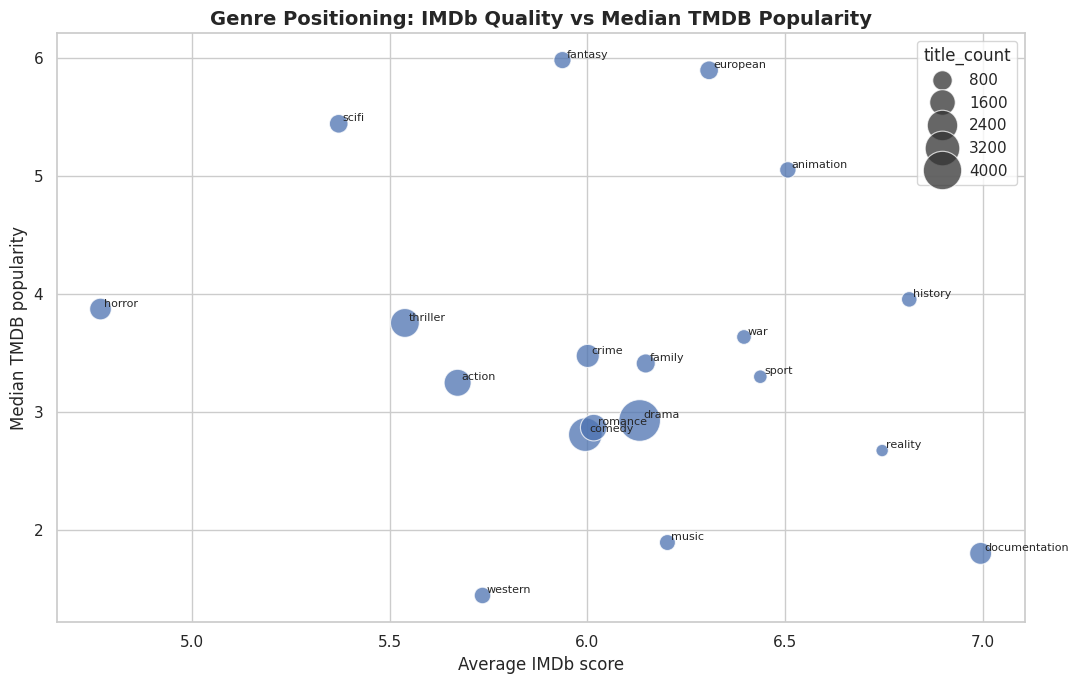

In [27]:
genre_position = (
    genre_df.groupby('genre')
    .agg(
        title_count=('id', 'size'),
        average_imdb=('imdb_score', 'mean'),
        median_popularity=('tmdb_popularity', 'median')
    )
    .query('title_count >= 100')
    .dropna()
)
plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=genre_position,
    x='average_imdb', y='median_popularity',
    size='title_count', sizes=(80, 900), alpha=0.75
)
for genre, row in genre_position.iterrows():
    plt.text(row['average_imdb'] + 0.01, row['median_popularity'] + 0.02, genre, fontsize=8)
finish_plot('Genre Positioning: IMDb Quality vs Median TMDB Popularity', 'Average IMDb score', 'Median TMDB popularity')

**Why this chart?** This multivariate bubble chart compares genre quality, popularity and catalogue size together.  
**Insight.** Large genres are not automatically the highest-rated, and some specialised genres combine good quality with lower mainstream visibility.  
**Business impact.** Marketing can identify underexposed quality segments and avoid relying on volume alone when selecting featured genres.

#### **Chart 16 — Top Production Countries**

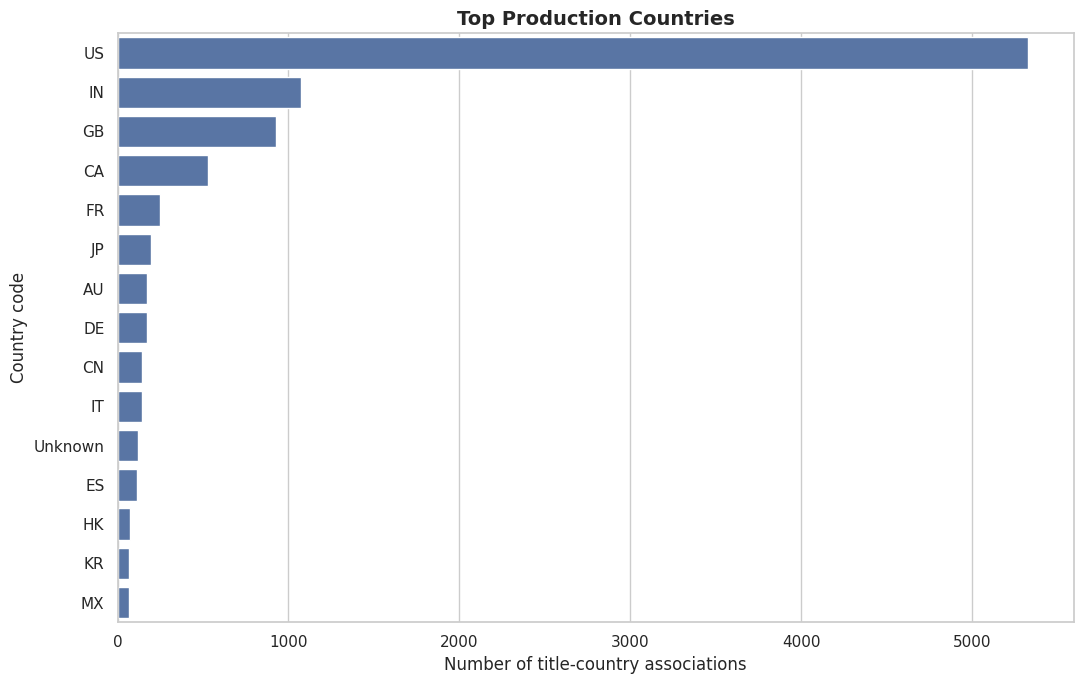

In [28]:
country_counts = country_df['country'].value_counts().head(15)
plt.figure(figsize=(11, 7))
sns.barplot(y=country_counts.index, x=country_counts.values, color='C0')
finish_plot('Top Production Countries', 'Number of title-country associations', 'Country code')

**Why this chart?** It provides a direct view of regional catalogue concentration.  
**Insight.** The largest contributors are **US, IN, GB, CA, FR**. The United States is dominant, while India and the United Kingdom provide substantial regional depth.  
**Business impact.** Regional acquisition and localisation investment can be aligned with both current strengths and underrepresented markets.

#### **Chart 17 — Country Quality versus Catalogue Size**

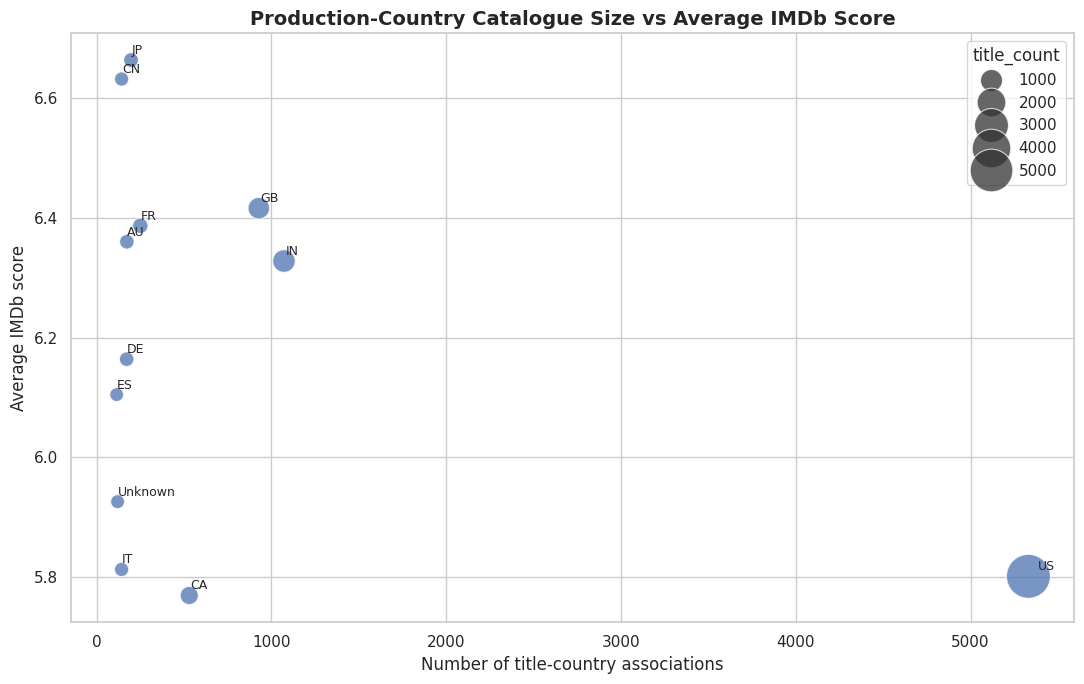

In [29]:
country_quality = (
    country_df.groupby('country')
    .agg(title_count=('id', 'size'), average_imdb=('imdb_score', 'mean'))
    .query('title_count >= 100')
    .dropna()
    .sort_values('average_imdb', ascending=False)
)
plt.figure(figsize=(11, 7))
sns.scatterplot(data=country_quality, x='title_count', y='average_imdb', size='title_count', sizes=(100, 1000), alpha=0.75)
for country, row in country_quality.iterrows():
    plt.text(row['title_count'] * 1.01, row['average_imdb'] + 0.01, country, fontsize=9)
finish_plot('Production-Country Catalogue Size vs Average IMDb Score', 'Number of title-country associations', 'Average IMDb score')

**Why this chart?** It tests whether catalogue volume and average audience rating move together across major production countries.  
**Insight.** High catalogue volume does not guarantee the highest average IMDb score; several smaller regional catalogues compare favourably on quality.  
**Business impact.** Regional content decisions should balance scale, quality, localisation cost and audience fit.

#### **Chart 18 — IMDb Score versus TMDB Score**

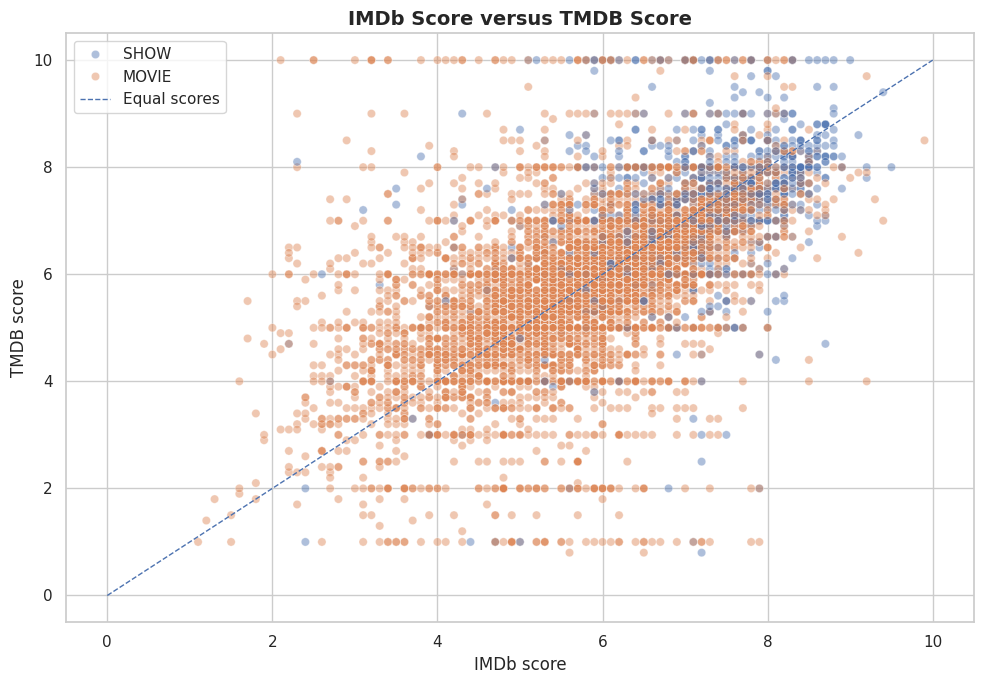

In [30]:
score_compare = df.dropna(subset=['imdb_score', 'tmdb_score'])
plt.figure(figsize=(10, 7))
sns.scatterplot(data=score_compare, x='imdb_score', y='tmdb_score', hue='type', alpha=0.45)
plt.plot([0, 10], [0, 10], linestyle='--', linewidth=1, label='Equal scores')
plt.legend()
finish_plot('IMDb Score versus TMDB Score', 'IMDb score', 'TMDB score')

**Why this chart?** A scatter plot evaluates agreement between two independent rating systems.  
**Insight.** IMDb and TMDB scores have a positive correlation of approximately **0.58**, but individual titles may differ materially between platforms.  
**Business impact.** Recommendation and merchandising systems should combine multiple quality signals rather than depend on one source.

#### **Chart 19 — Runtime versus IMDb Score**

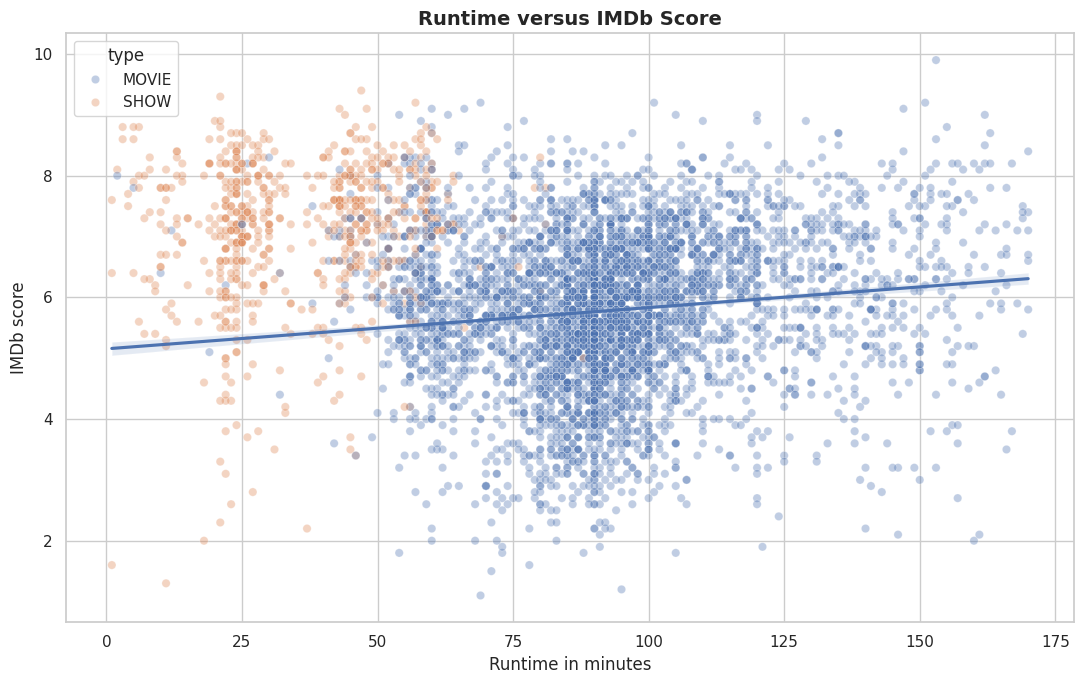

In [31]:
runtime_score = df.dropna(subset=['imdb_score']).copy()
runtime_score = runtime_score[runtime_score['runtime'] <= runtime_score.groupby('type')['runtime'].transform('quantile', 0.99)]
plot_sample = runtime_score.sample(min(5000, len(runtime_score)), random_state=42)
plt.figure(figsize=(11, 7))
sns.scatterplot(data=plot_sample, x='runtime', y='imdb_score', hue='type', alpha=0.35)
sns.regplot(data=runtime_score[runtime_score['type'].eq('MOVIE')], x='runtime', y='imdb_score', scatter=False, label='Movie trend')
finish_plot('Runtime versus IMDb Score', 'Runtime in minutes', 'IMDb score')

**Why this chart?** It examines whether longer content is systematically rated better or worse.  
**Insight.** Runtime has only a weak relationship with IMDb score; duration alone is not a dependable quality signal.  
**Business impact.** Content decisions should not favour longer or shorter titles without considering genre, audience and storytelling quality.

#### **Chart 20 — Top-Rated Titles with Meaningful Vote Volume**

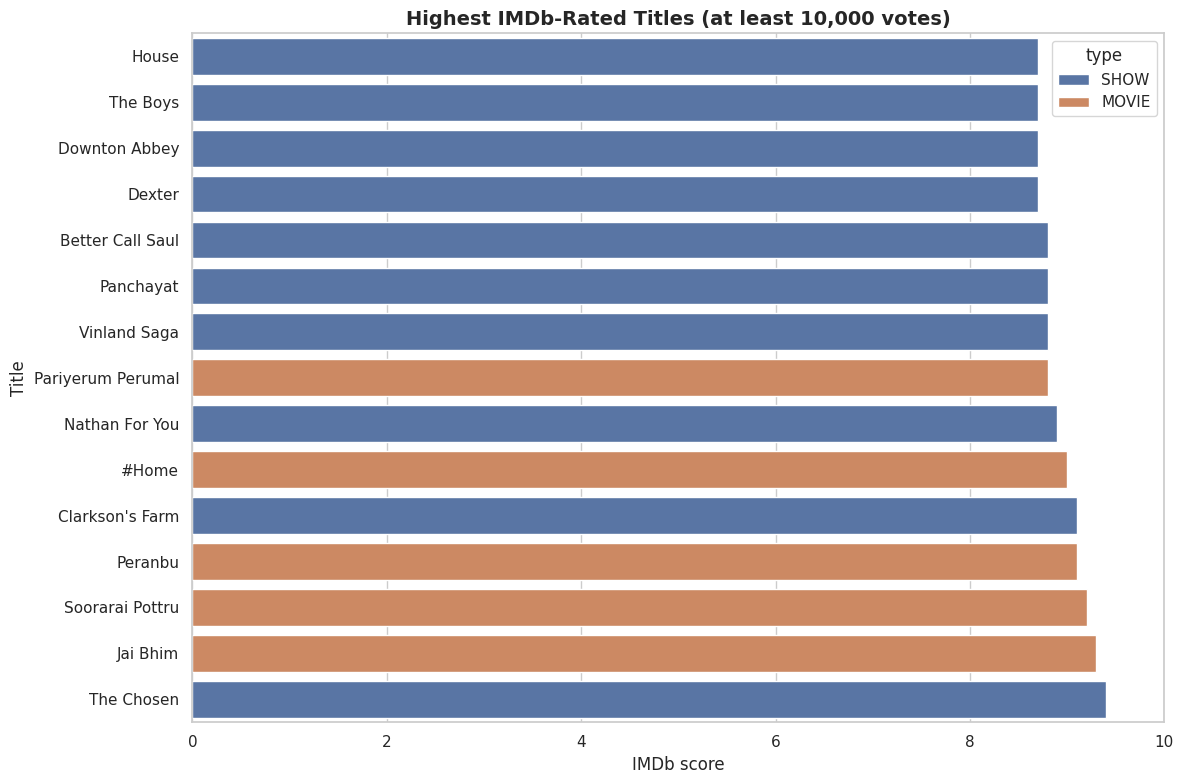

In [32]:
top_rated_titles = (
    df[df['imdb_votes'].ge(10000) & df['imdb_score'].notna()]
    .nlargest(15, ['imdb_score', 'imdb_votes'])
    .sort_values('imdb_score')
)
plt.figure(figsize=(12, 8))
sns.barplot(data=top_rated_titles, y='title', x='imdb_score', hue='type', dodge=False)
plt.xlim(0, 10)
finish_plot('Highest IMDb-Rated Titles (at least 10,000 votes)', 'IMDb score', 'Title')

**Why this chart?** A vote threshold makes the ranking more credible than using score alone.  
**Insight.** **The Chosen** is the highest-rated qualifying title in this dataset with an IMDb score of **9.4**. Both movies and shows appear among the strongest audience-rated titles.  
**Business impact.** High-rated, high-vote titles are strong candidates for prominent placement, retention campaigns and “critically loved” collections.

#### **Chart 21 — Most Popular Titles on TMDB**

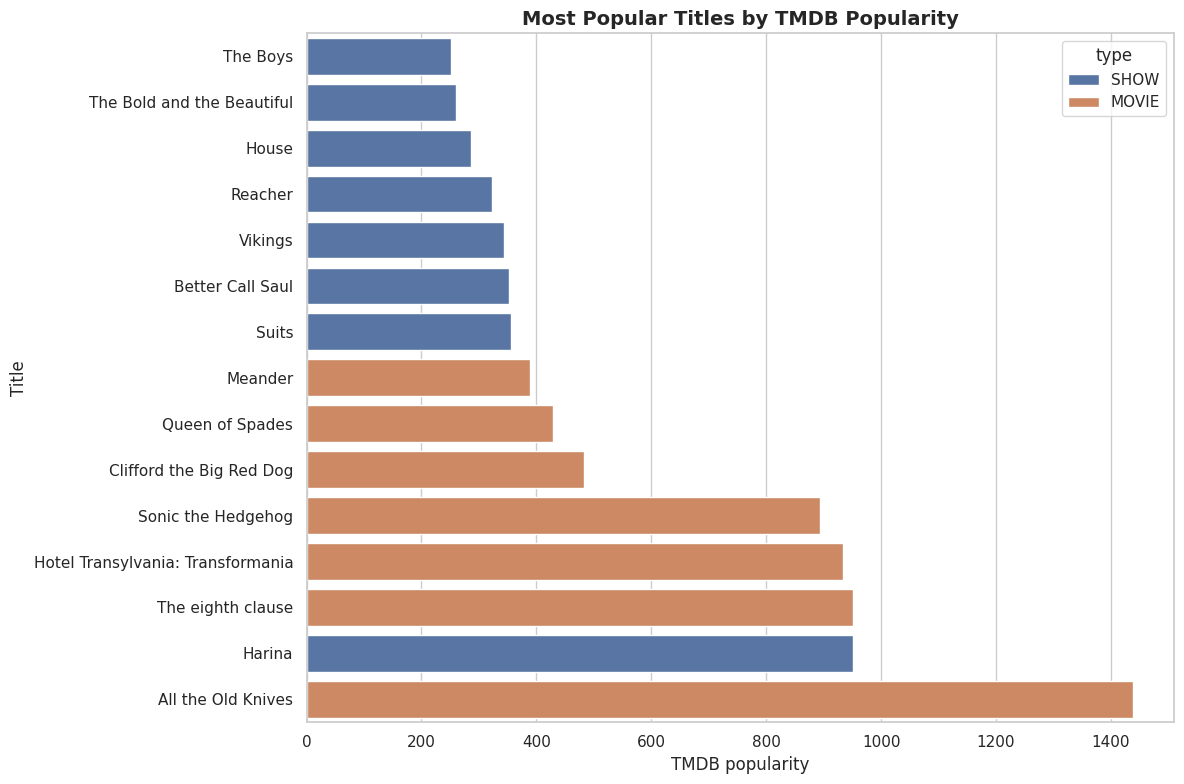

In [33]:
top_popular_titles = (
    df[df['tmdb_popularity'].notna()]
    .nlargest(15, 'tmdb_popularity')
    .sort_values('tmdb_popularity')
)
plt.figure(figsize=(12, 8))
sns.barplot(data=top_popular_titles, y='title', x='tmdb_popularity', hue='type', dodge=False)
finish_plot('Most Popular Titles by TMDB Popularity', 'TMDB popularity', 'Title')

**Why this chart?** It identifies titles receiving exceptional attention, regardless of rating.  
**Insight.** **All the Old Knives** has the highest TMDB popularity value in the dataset. The list differs from the highest-rated ranking, demonstrating that visibility and perceived quality are separate concepts.  
**Business impact.** Popular titles can drive acquisition and click-through, but quality checks are needed before treating popularity as a satisfaction indicator.

#### **Chart 22 — Format Mix by Decade**

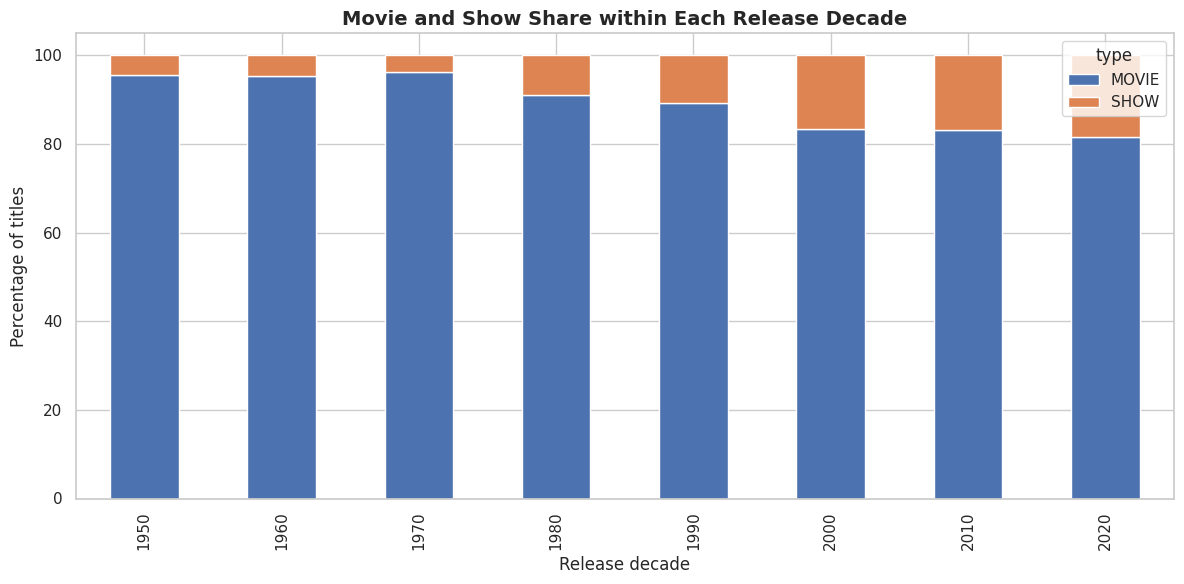

In [34]:
decade_type = pd.crosstab(df['decade'], df['type'])
decade_type = decade_type.loc[decade_type.index >= 1950]
decade_type_pct = decade_type.div(decade_type.sum(axis=1), axis=0) * 100
decade_type_pct.plot(kind='bar', stacked=True, figsize=(12, 6))
finish_plot('Movie and Show Share within Each Release Decade', 'Release decade', 'Percentage of titles')

**Why this chart?** A 100% stacked bar chart separates absolute growth from changes in content mix.  
**Insight.** Movies dominate every decade, but shows form a larger share of recent catalogue additions than in early decades.  
**Business impact.** The changing mix can guide long-term portfolio planning and format-specific licensing strategies.

#### **Chart 23 — Correlation Heatmap**

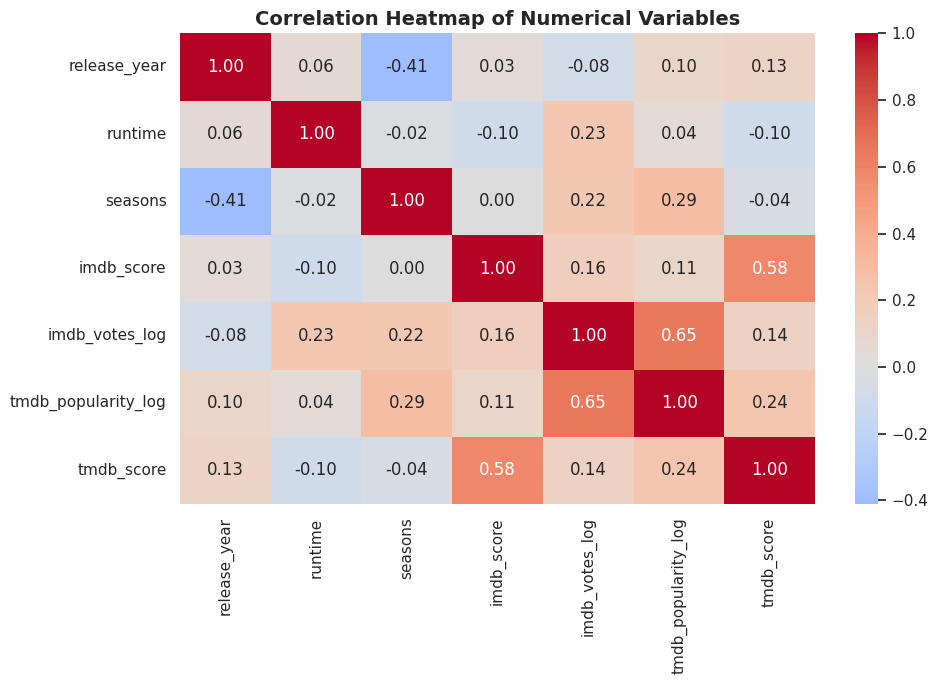

In [35]:
numeric_columns = [
    'release_year', 'runtime', 'seasons', 'imdb_score',
    'imdb_votes_log', 'tmdb_popularity_log', 'tmdb_score'
]
correlation_matrix = df[numeric_columns].corr()
plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f')
finish_plot('Correlation Heatmap of Numerical Variables')

**Why this chart?** A heatmap summarises linear relationships across all principal numerical variables.  
**Insight.** IMDb and TMDB scores have the clearest positive relationship. Vote volume and popularity are related but not equivalent, while runtime has weak relationships with ratings.  
**Business impact.** Models and dashboards should avoid treating weakly related variables as substitutes and should monitor multicollinearity before predictive modelling.

#### **Chart 24 — Pair Plot of Core Performance Variables**

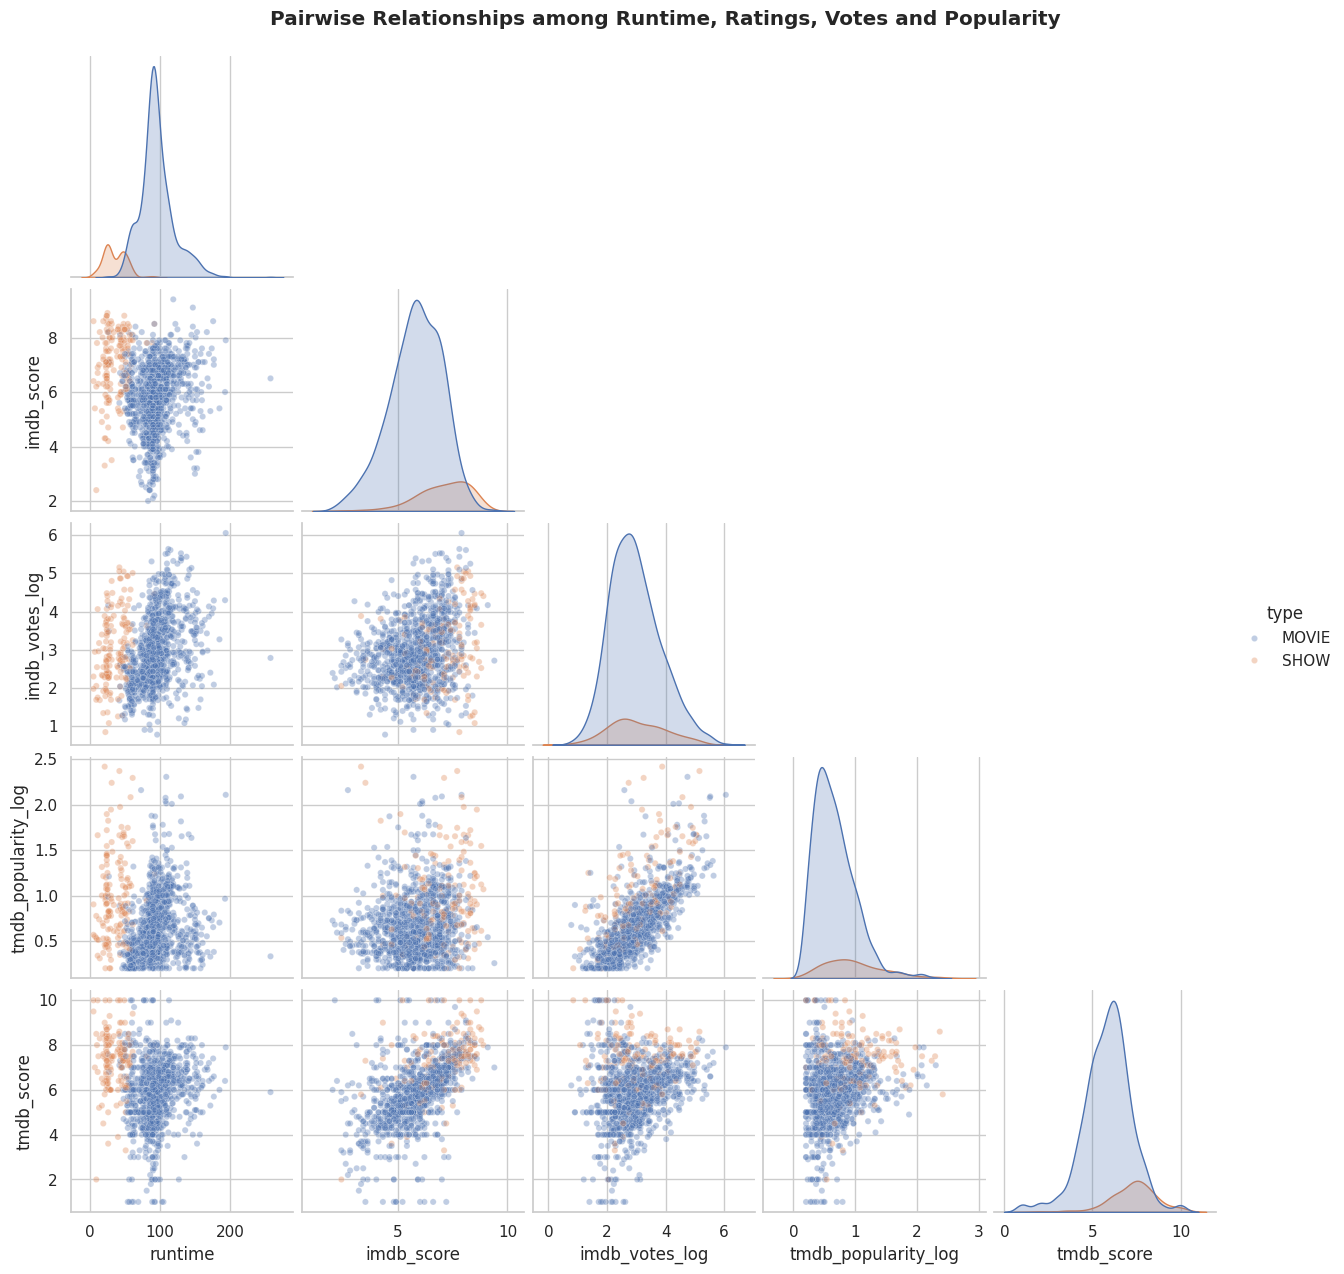

In [36]:
pair_columns = ['type', 'runtime', 'imdb_score', 'imdb_votes_log', 'tmdb_popularity_log', 'tmdb_score']
pair_data = df[pair_columns].dropna().sample(min(1200, len(df[pair_columns].dropna())), random_state=42)
sns.pairplot(pair_data, hue='type', corner=True, plot_kws={'alpha': 0.35, 's': 20})
plt.suptitle('Pairwise Relationships among Runtime, Ratings, Votes and Popularity', y=1.02, fontweight='bold')
plt.show()

**Why this chart?** The pair plot provides a compact multivariate overview and helps reveal non-linear patterns, clusters and outliers.  
**Insight.** Shows generally occupy higher rating ranges, whereas movies cover a broader runtime range. Popularity and vote volume remain strongly skewed even after log transformation.  
**Business impact.** These patterns indicate that format segmentation and transformed engagement variables are important for future predictive or clustering work.

## **5. Solution to the Business Objective**

### Recommendations

1. **Balance scale with quality.** Use IMDb score, TMDB score, vote volume and popularity together when selecting titles for prominent placement.
2. **Strengthen episodic retention.** Shows are a smaller catalogue segment but receive stronger median audience ratings, making quality series important for sustained engagement.
3. **Use genre portfolio mapping.** Protect high-volume genres while selectively expanding high-quality specialised genres such as documentary and history.
4. **Develop regional strategies.** The catalogue is US-led, but India, the UK and other countries provide meaningful scale or quality opportunities. Regional recommendations should consider language and localisation needs.
5. **Improve metadata completeness.** Age-certification gaps weaken parental controls and filtering. Rating and identifier coverage should also be monitored as a catalogue-quality KPI.
6. **Separate popularity from satisfaction.** Trending titles should be evaluated for quality and audience depth before long-term promotion decisions.
7. **Create context-aware shelves.** Runtime and season information can support quick-watch, weekend-movie, limited-series and long-binge collections.
8. **Validate time-based conclusions.** Treat the final dataset year cautiously when coverage may be incomplete.

# **Conclusion**

The Amazon Prime catalogue analysed in this project contains **9,868 unique titles** and is strongly dominated by movies. Its historical coverage is broad, but most catalogue volume comes from recent decades. Drama, comedy, thriller and action are the largest genres, and production is concentrated in the United States with substantial contributions from India, the United Kingdom and Canada.

The analysis also shows that catalogue quantity, popularity and audience quality are different dimensions. Shows form a smaller part of the catalogue but have higher median IMDb and TMDB scores than movies. IMDb and TMDB ratings generally move together, while popularity and voting volume are heavily skewed toward a relatively small number of titles. Runtime has only a weak relationship with ratings, so duration should not be treated as a proxy for quality.

From a business perspective, Amazon Prime can gain more value by combining multiple audience signals, strengthening metadata completeness, promoting high-quality regional and specialised content, and balancing blockbuster visibility with long-tail discovery. These findings provide a foundation for deeper work such as recommendation-system features, content segmentation, popularity prediction and regional catalogue optimisation.

